# Hyperbolic Phonon Polaritons in Planar hBN

This notebook develops the planar reference model used to interpret the cavity calculations. We first examine the anisotropic hBN permittivity and its hyperbolic isofrequency curves. We then calculate the guided slab dispersion, connect it to the real-space ray picture and finally evaluate the reflected Green tensor, local density of optical states and Purcell enhancement above the slab.


## Tools and material model


In [40]:
import numpy as np 
import matplotlib.pyplot as plt
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")
from matplotlib.colors import LogNorm
import matplotlib.ticker as ticker
import cmasher as cmr

import sys
sys.path.append('..')

In [41]:
from methods.hBN_permittivity import get_epsilon
from methods.hBN_permittivity import omega_LO_x_pure11b, omega_TO_x_pure11b
from methods.hpp_dispersion import slab_dispersion, compute_lengths
from methods.green_function import compute_ldos, ref_p

The `pure` (type of hBN) material model returns callable in-plane and out-of-plane permittivities. All frequencies below are photon energies in eV and all lengths are in nm.


In [42]:
eps_2x, eps_2z = get_epsilon(hbn_type='pure') 

## Permittivity in the second Reststrahlen band

The in-plane and out-of-plane dielectric responses are evaluated around the upper Reststrahlen band. In this interval, the real parts of the two principal permittivities have opposite signs, producing a type-II hyperbolic response. The imaginary parts quantify material absorption. The vertical guides mark the in-plane transverse- and longitudinal-optical phonon energies.


In [43]:
energy_eV = np.linspace(omega_TO_x_pure11b*0.9, omega_LO_x_pure11b*1.2, 300)
eps_x = eps_2x(energy_eV)
eps_z = eps_2z(energy_eV)

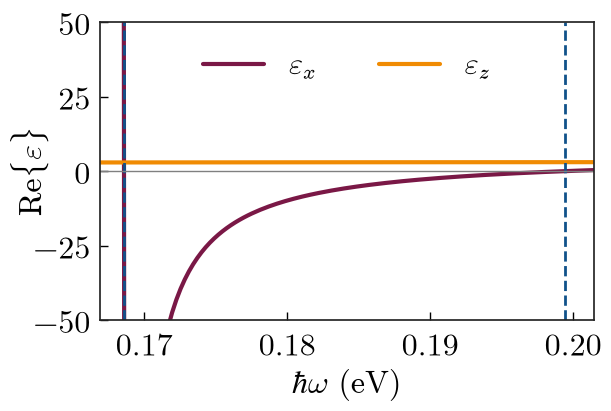

In [44]:
subset_colors = cmr.take_cmap_colors('cmr.rainforest', N=5, cmap_range=(0.2,0.8))
subset_colors2 = cmr.take_cmap_colors('cmr.ember', N=5, cmap_range=(0.2,0.8))

fig, ax = plt.subplots(figsize=(6,4))

ax.plot(energy_eV, np.real(eps_x), c=subset_colors2[1], label=r'$\varepsilon_x$', lw=3)
ax.plot(energy_eV, np.real(eps_z), c=subset_colors2[-1], label=r'$\varepsilon_z$', lw=3)

ax.set_xlim(omega_TO_x_pure11b*0.99, omega_LO_x_pure11b*1.01)
ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=23)
ax.set_ylabel(r'$\text{Re} \{ \varepsilon \}$', fontsize=23, labelpad=-12)
ax.tick_params(axis='both', labelsize=23)

ax.axvline(omega_TO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2)
ax.axvline(omega_LO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2)
ax.legend(ncols=2, prop={'size': 22}, loc='upper center')
ax.axhline(0, c='gray', linestyle='solid', lw=1)

ax.set_ylim(-50,50);

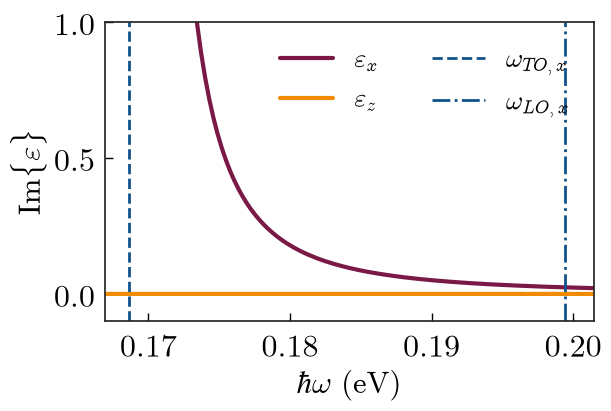

In [45]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(energy_eV, np.imag(eps_x), c=subset_colors2[1], label=r'$\varepsilon_x$', lw=3)
ax.plot(energy_eV, np.imag(eps_z), c=subset_colors2[-1], label=r'$\varepsilon_z$', lw=3)

ax.set_ylim(-0.1, 1)
ax.set_xlim(omega_TO_x_pure11b*0.99, omega_LO_x_pure11b*1.01)
ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\text{Im} \{ \varepsilon \}$', fontsize=22, labelpad=5)
ax.tick_params(axis='x', which='both', top=False)
ax.tick_params(axis='both', labelsize=23)

ax.axvline(omega_TO_x_pure11b, c=subset_colors[1], linestyle='--', label=r'$\omega_{TO,x}$')
ax.axvline(omega_LO_x_pure11b, c=subset_colors[1], linestyle='-.', label=r'$\omega_{LO,x}$')
ax.legend(ncols=2, prop={'size': 19})

## Bulk isofrequency curves

For a uniaxial medium with optical axis along $z$, extraordinary waves obey

$$\frac{k_x^2}{\varepsilon_z}+\frac{k_z^2}{\varepsilon_x}=k_0^2.$$

The opposite signs of $\varepsilon_x$ and $\varepsilon_z$ open the isofrequency contour into a hyperbola. 


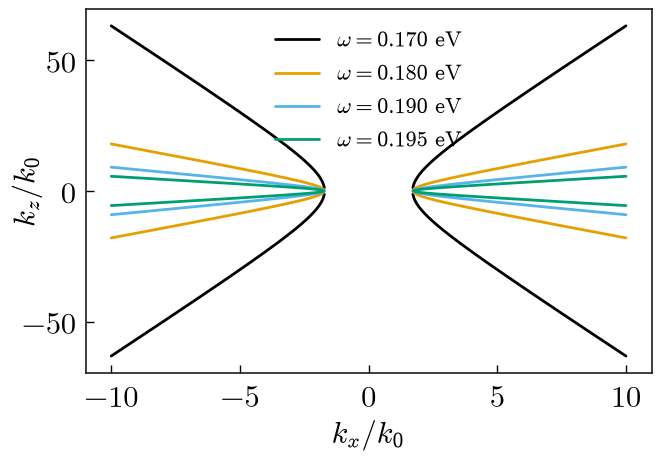

In [46]:
kx_negative = np.linspace(-10, -1, 600)
kx_positive = np.linspace(1, 10, 600)
energies_eV = np.array([0.17, 0.18, 0.19, 0.195])

colors = ['#000000', '#E69F00', '#56B4E9', '#009E73']
fig, ax = plt.subplots()

for index, energy in enumerate(energies_eV):
    epsx = np.real(eps_2x(energy))
    epsz = np.real(eps_2z(energy))

    # Retain only the bulk branches with a real longitudinal wavevector.
    argument_negative = epsx - kx_negative**2 * epsx / epsz
    argument_positive = epsx - kx_positive**2 * epsx / epsz
    mask_negative = argument_negative >= 0
    mask_positive = argument_positive >= 0

    kz_negative = np.sqrt(argument_negative[mask_negative])
    kz_positive = np.sqrt(argument_positive[mask_positive])

    ax.plot(kx_negative[mask_negative], kz_negative, c=colors[index], lw=2,
            label=rf'$\omega = {energy:.3f} \text{{ eV}}$')
    ax.plot(kx_negative[mask_negative], -kz_negative, c=colors[index], lw=2)
    ax.plot(kx_positive[mask_positive], kz_positive, c=colors[index], lw=2)
    ax.plot(kx_positive[mask_positive], -kz_positive, c=colors[index], lw=2)

ax.set_xlabel(r'$k_x/k_0$', fontsize=22)
ax.set_ylabel(r'$k_z/k_0$', fontsize=22, labelpad=-15)
ax.tick_params(axis='both', labelsize=22)
ax.legend(loc='upper center');

## Guided-mode dispersion of a finite slab

We now impose the slab boundary conditions for a $25\,\mathrm{nm}$ hBN film. `slab_dispersion` returns the complex normalized in-plane wavevector $\kappa_x=k_x/k_0$ for each branch index $n$. Its real part sets the polariton wavelength, while its imaginary part describes propagation loss.


In [47]:
# Calculate the first seven guided branches of a 25 nm slab.
omega_0_ls = np.linspace(omega_TO_x_pure11b*1.01, omega_LO_x_pure11b, 100)
l_val_ls = [i for i in range(7)]

k_compl = slab_dispersion(omega_0_ls, l_val_ls, d=25)
lam_x, delta_x = compute_lengths(k_compl, omega_0_ls)

The first plot shows the real and imaginary parts of $\kappa_x$ across the Reststrahlen band. Comparing the branches reveals how confinement and attenuation evolve with mode order.


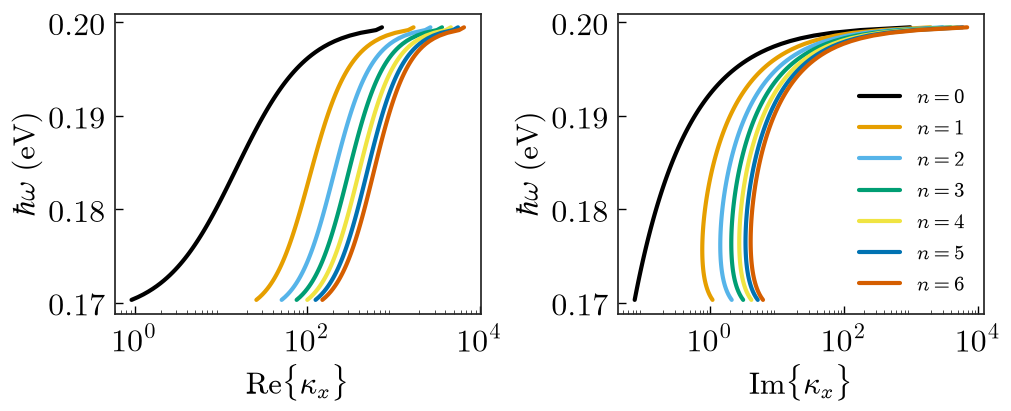

In [48]:
fig, ax = plt.subplots(figsize=(10,4), nrows=1, ncols=2)

for i in range(len(l_val_ls)):
    ax[0].plot(np.real(k_compl[i]), omega_0_ls, '-', lw=3)

ax[0].set_xlabel(r'$\mathrm{Re}\{\kappa_x\}$', fontsize=22)
ax[0].set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=22)
ax[0].set_xscale('log')
ax[0].tick_params(axis='both', labelsize=23)
ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=12))

for i in range(len(l_val_ls)):
    ax[1].plot(np.imag(k_compl[i]), omega_0_ls, '-', lw=3, 
               label=r'$n = %i$' % i)

ax[1].set_xlabel(r'$\mathrm{Im}\{\kappa_x\}$', fontsize=22)
ax[1].set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=22)
ax[1].legend(prop={'size': 15})
ax[1].set_xscale('log')
ax[1].tick_params(axis='both', labelsize=23)
ax[1].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=12))

The same solutions are expressed as the in-plane wavelength $\lambda_x=2\pi/\mathrm{Re}(k_x)$ and propagation length $\delta_x=1/[2\,\mathrm{Im}(k_x)]$. These dimensional quantities make the confinement–loss tradeoff easier to compare with the slab thickness.


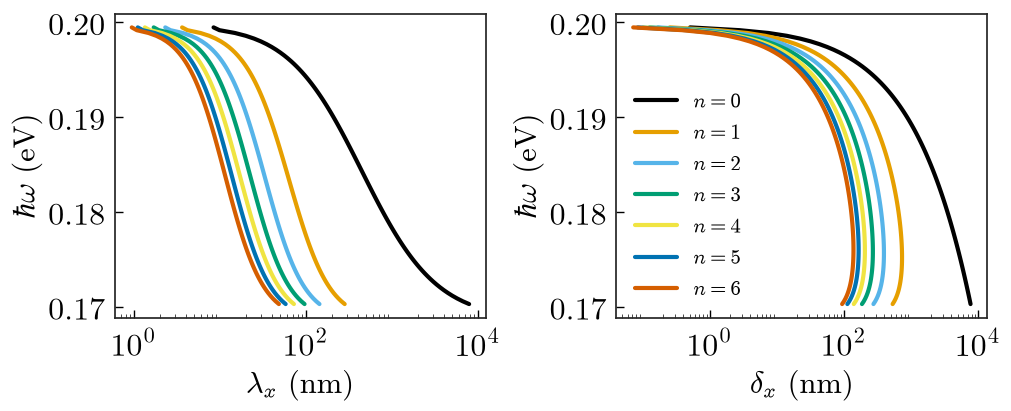

In [49]:
fig, ax = plt.subplots(figsize=(10,4), nrows=1, ncols=2)

for i in range(len(l_val_ls)):
    ax[0].plot(lam_x[i], omega_0_ls, '-', lw=3)

ax[0].set_xlabel(r'$\lambda_x \text{ (nm)}$', fontsize=22)
ax[0].set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=22)
ax[0].set_xscale('log')
ax[0].tick_params(axis='both', labelsize=23)
ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=12))


for i in range(len(l_val_ls)):
    ax[1].plot(delta_x[i], omega_0_ls, '-', lw=3, 
               label=r'$n = %i$' % i)

ax[1].set_xlabel(r'$\delta_x \text{ (nm)}$', fontsize=22)
ax[1].set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=22)
ax[1].legend(prop={'size': 15})
ax[1].set_xscale('log')
ax[1].tick_params(axis='both', labelsize=23)
ax[1].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=12))

To compare many mode orders at fixed photon energy, we next plot the propagation length directly against $\mathrm{Re}(\kappa_x)$. Increasing in-plane momentum generally corresponds to stronger confinement and shorter propagation.


In [50]:
# Resolve many mode orders at a small set of representative energies.
omega_0_ls = np.array([0.177,0.181,0.185,0.189,0.193,0.197])
l_val_ls = np.linspace(0, 100, 101, dtype=int)

k_compl = slab_dispersion(omega_0_ls, l_val_ls, d=25)
lam_x, delta_x = compute_lengths(k_compl, omega_0_ls)

Text(0, 0.5, '$\\delta_x \\text{ (nm)}$')

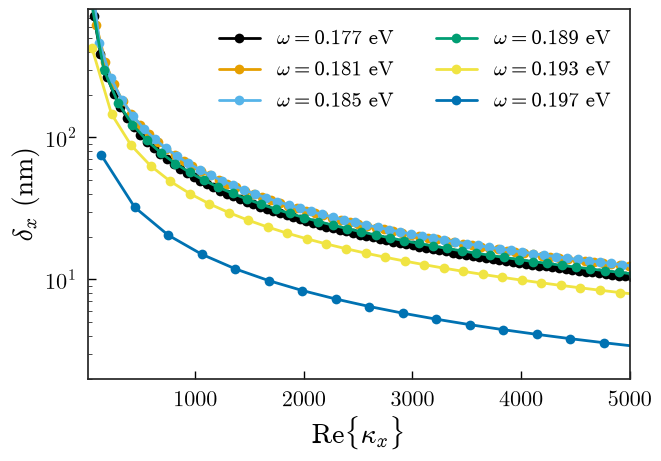

In [51]:
fig, ax = plt.subplots()
for i in range(omega_0_ls.shape[0]):
    ax.plot(np.real(k_compl[:,i]), delta_x[:,i], '-o', linewidth=2, label=r'$\omega = %.3f \text{ eV}$' % omega_0_ls[i])

ax.legend(prop={'size': 15}, ncols=2)
ax.set_yscale('log')
ax.set_xlim(10, 5000)
ax.set_ylim(2, 800)
ax.set_xlabel(r'$\mathrm{Re}\{\kappa_x\}$', fontsize=20)
ax.set_ylabel(r'$\delta_x \text{ (nm)}$', fontsize=20);

## Real-space ray picture

In the large-momentum limit, the hyperbolic dispersion defines a preferred group-velocity direction. We use

$$\theta_g=\tan^{-1}\!\sqrt{-\varepsilon_z/\varepsilon_x}$$

to connect the momentum-space response to a ray propagating and reflecting inside the slab. Because the permittivities are lossy, the angle is generally complex; the plots below show its real part.


In [52]:
def get_angle(eps_x, eps_z):
    """Return the complex hyperbolic group-velocity angle in radians."""
    return np.arctan(np.sqrt(-eps_z / eps_x))

In [53]:
energy_eV = np.linspace(0.165, 0.205, 100) 
eps_x = eps_2x(energy_eV)
eps_z = eps_2z(energy_eV)
thetas = get_angle(eps_x=eps_x, eps_z=eps_z)

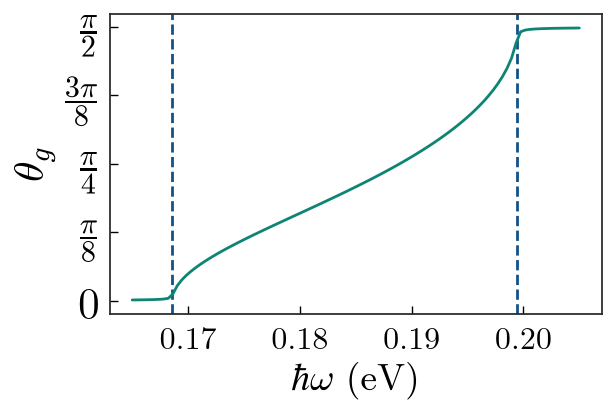

In [62]:
subset_colors = cmr.take_cmap_colors('cmr.rainforest', N=5, cmap_range=(0.2,0.8))

fig, ax = plt.subplots(figsize=(6,4))

ax.plot(energy_eV, np.real(thetas), c=subset_colors[-3], lw=2)
ax.set_yticks([0,np.pi/8,np.pi/4,3*np.pi/8,np.pi/2]);
ax.set_yticklabels(['0',r'$\frac{\pi}{8}$',r'$\frac{\pi}{4}$',
                    r'$\frac{3\pi}{8}$',r'$\frac{\pi}{2}$'], fontsize=25);

ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=27)
ax.set_ylabel(r'$\theta_{g}$', fontsize=30)

ax.tick_params(axis='both', labelsize=23)
ax.tick_params(axis='y', labelsize=31)
ax.axvline(omega_TO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2, zorder=1)
ax.axvline(omega_LO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2, zorder=1);

### First reflection point

For a ray launched at the upper interface, the lateral position of the $\ell$-th return to that interface is estimated as

$$x_\ell=(2\ell-1)d\tan(\pi/2-\theta_g).$$

We first evaluate the initial return ($\ell=1$) for a $25\,\mathrm{nm}$ slab.


In [55]:
def get_bounce_distance(ell, eps_2x, eps_2z, d):
    """Return the lateral position of the ell-th upper-interface return."""
    if ell < 1:
        raise ValueError("ell must be a positive integer")
    angle = get_angle(eps_2x, eps_2z)
    return (2 * ell - 1) * d * np.tan(np.pi / 2 - angle)


In [56]:
hbn_width = 25  # nm
omega_ls = np.linspace(0.172, 0.199, 100) # eV
eps_2x_val = eps_2x(omega_ls)
eps_2z_val = eps_2z(omega_ls)
x1 = get_bounce_distance(ell=1, eps_2x=eps_2x_val, eps_2z=eps_2z_val, d=hbn_width)

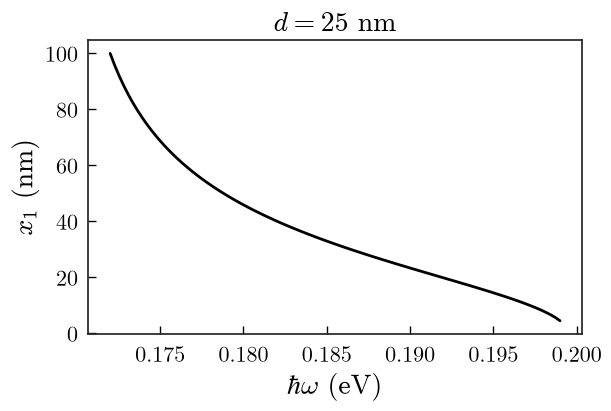

In [61]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(omega_ls, np.real(x1))
ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$x_1 \text{ (nm)}$', fontsize=20)
ax.set_title(r'$d = %.0f \text{ nm}$' % hbn_width, fontsize=20);

### Higher-order reflections

We retain the same slab thickness and track several subsequent returns. Their frequency dependence illustrates how the changing hyperbolic ray angle controls the lateral spacing of successive reflections.


In [58]:
hbn_width = 25  # nm
omega_ls = np.linspace(0.172, 0.199, 100) # eV
eps_2x_val = eps_2x(omega_ls)
eps_2z_val = eps_2z(omega_ls)

ell_ls = [1,2,3,4,5]

x = []
for ell in ell_ls:
    val = get_bounce_distance(ell=ell, eps_2x=eps_2x_val, eps_2z=eps_2z_val, d=hbn_width)
    x.append(val)

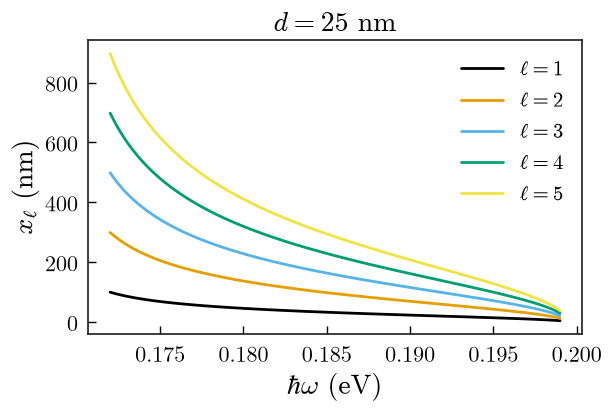

In [60]:
fig, ax = plt.subplots(figsize=(6,4))

for ell in ell_ls:
    ax.plot(omega_ls, np.real(x[ell-1]), label=r'$\ell = %i$' % ell)

ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$x_{\ell} \text{ (nm)}$', fontsize=20)
ax.set_title(r'$d = %.0f \text{ nm}$' % hbn_width, fontsize=20)
ax.legend(prop={'size': 15});

The following view shows the same data over a narrower, higher-energy window, where the reflection positions vary most rapidly.


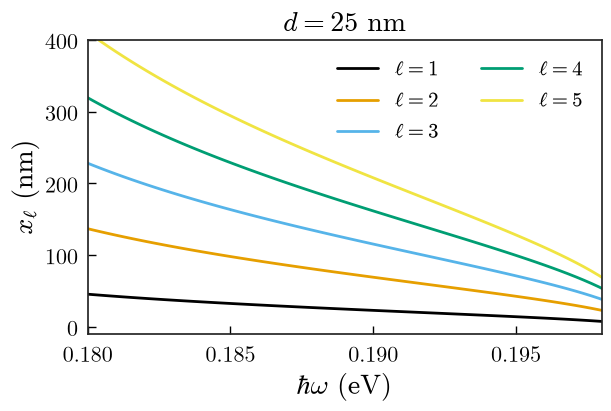

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))

for ell in ell_ls:
    ax.plot(omega_ls, np.real(x[ell-1]), label=r'$\ell = %i$' % ell)

ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$x_{\ell} \text{ (nm)}$', fontsize=20)
ax.set_title(r'$d = %.0f \text{ nm}$' % hbn_width, fontsize=20)
ax.legend(prop={'size': 15}, ncols=2)
ax.set_xlim(0.180, 0.198)
ax.set_ylim(-10, 400);

### Dependence on slab thickness

Finally, we compare the first return position for several hBN thicknesses. At fixed frequency, the geometric ray model predicts a return distance that scales linearly with $d$.


In [20]:
omega_ls = np.linspace(0.172, 0.199, 100) # eV
eps_2x_val = eps_2x(omega_ls)
eps_2z_val = eps_2z(omega_ls)

ell_ls = [1,2,3,4,5]

hbn_width_ls = [3,5,10]

x = []
for hbn_width in hbn_width_ls:
    x.append([])
    for ell in ell_ls:
        val = get_bounce_distance(ell=ell, eps_2x=eps_2x_val, eps_2z=eps_2z_val, d=hbn_width)
        x[-1].append(val)
x_dat = np.array(x)

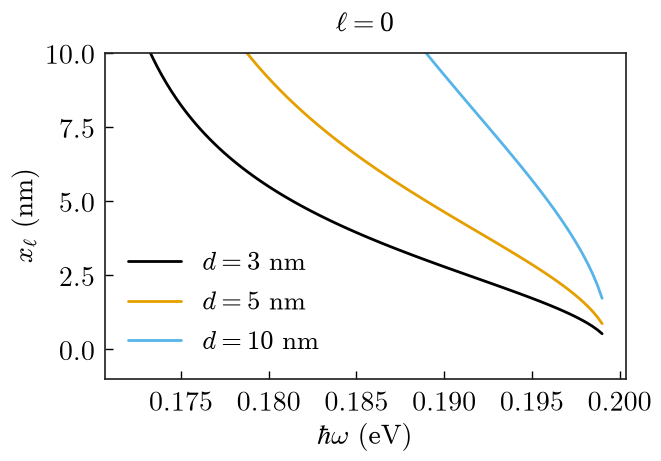

In [22]:
fig, ax = plt.subplots()

for i in range(3):
    ax.plot(omega_ls, np.real(x_dat[i,0]), 
            label=r'$d = %.0f \text{ nm}$' % hbn_width_ls[i])

ax.set_ylim(-1, 10)
ax.set_title(r'$\ell = 1$', fontsize=20, pad=15)
ax.set_xlabel(r'$\hbar \omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$x_{\ell} \text{ (nm)}$', fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.legend(prop={'size': 19});

## Green tensor and local density of states

The ray picture is useful geometrically, but the electromagnetic response is determined by the full Sommerfeld integral. We therefore calculate the p-polarized slab reflection coefficient and the scattering Green tensor resolved by the normalized in-plane momentum $\kappa=k_\parallel/k_0$.


### Momentum-resolved reflection coefficient

We use a $25\,\mathrm{nm}$ hBN slab between air half-spaces. The imaginary part of $r_p(\kappa,\omega)$ exposes the guided polariton branches as momentum-dependent resonances. The horizontal guides select the energies examined later in the Green-function integrand.


In [63]:
omega_ls = np.linspace(0.165, 0.205, 100) # eV
d = 25
hdist = 1
eps_1, eps_3 = 1.0, 1.0
eps_2x_val, eps_2z_val = eps_2x(omega_ls), eps_2z(omega_ls)

kmax = 5e3
num_int = 1e5
k_vals = np.linspace(0.1, kmax, int(num_int))

# Store r_p on the full frequency–momentum grid.
refl_res = np.zeros((omega_ls.shape[0],k_vals.shape[0]), dtype=complex)

for i in range(len(omega_ls)):

    k0 = 2.0 * np.pi / (1240 / omega_ls[i])

    refl_val = ref_p(
        kap=k_vals,
        eps_2x=eps_2x_val[i],
        eps_2z=eps_2z_val[i],
        eps_1=eps_1,
        eps_3=eps_3,
        d=d,
        k0=k0
    )

    refl_res[i] = refl_val

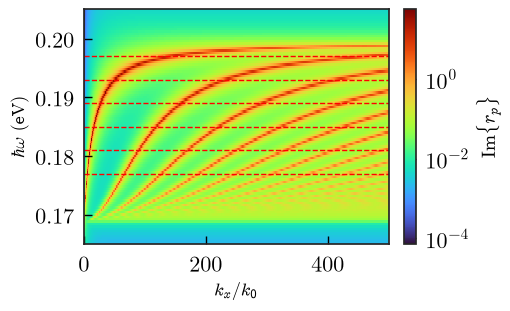

In [64]:
fig, ax = plt.subplots(figsize=(5,3))
im = ax.imshow(np.imag(refl_res), origin='lower', aspect='auto', norm=LogNorm(),
               extent=[k_vals[0],k_vals[-1],omega_ls[0],omega_ls[-1]])#, norm=LogNorm())
cbar = fig.colorbar(im)
cbar.ax.set_ylabel(r'$\text{Im}\{ r_p \}$', fontsize=14)
ax.set_xlabel(r'$k_{x}/ k_0$', fontsize=13)
ax.set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=13)
ax.set_xlim(0, 500)

lines = [0.177,0.181,0.185,0.189,0.193,0.197]
for li in lines:
    ax.axhline(li, linestyle='--', lw=1, c='red')

### Momentum-resolved Green-function integrand

We next place a $z$-oriented dipole $1\,\mathrm{nm}$ above the slab and evaluate the reflected Green tensor. The plotted evanescent integrand is normalized separately at each selected energy so that its dominant momentum scales can be compared directly.


In [65]:
omega_ls = np.linspace(0.165, 0.205, 100) # eV
d = 25.0
hdist = 1.0
dip_dir = np.array([0,0,1])
eps_1, eps_3 = 1.0, 1.22**2
eps_2x_val, eps_2z_val = eps_2x(omega_ls), eps_2z(omega_ls)

kmax = 5e3
num_int = 1e4

# Integrate the Green tensor for a z-oriented dipole above the slab.
ldos_res = compute_ldos(
    omega_ls=omega_ls,
    eps_1=eps_1,
    eps_2x=eps_2x_val,
    eps_2z=eps_2z_val,
    eps_3=eps_3,
    d=d,
    hdist=hdist,
    dip_dir=dip_dir,
    kmax=kmax,
    num_int=num_int
)

/var/folders/b8/0k3ny3sn1l3bkspn2m2vqf000000gn/T/ipykernel_9863/1331139562.py:3: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(wspace=0, hspace=0);


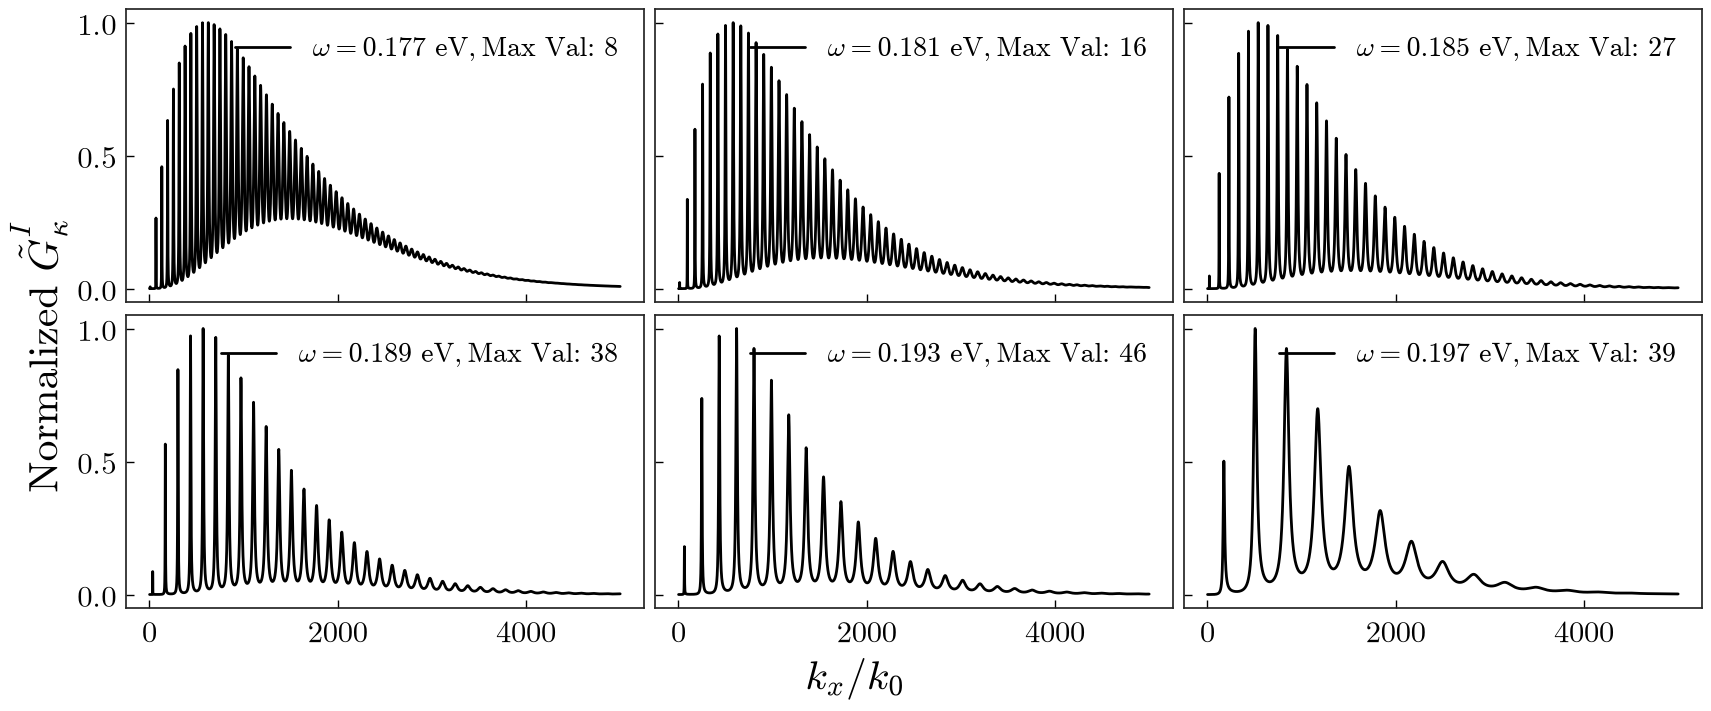

In [66]:
nrows, ncols = 2, 3
fig, ax = plt.subplots(figsize=(17,7), nrows=nrows, ncols=ncols, sharey=True, sharex=True)
fig.subplots_adjust(wspace=0, hspace=0);

indx_ls = [[30,40,50],[60,70,80]]

for i in range(nrows):
    for j in range(ncols):

        indx = indx_ls[i][j]
        k_vals = ldos_res['k_vals'][indx]
        gf_vals = ldos_res['gf_k'][indx]
    
        max_val = np.max(gf_vals)
        gf_vals_norm = gf_vals / np.max(gf_vals) 

        ax[i,j].plot(k_vals, gf_vals_norm, label=r'$\omega = %.3f \text{ eV}, \text{Max Val: } %.0f $' % (omega_ls[indx],max_val)) 
        ax[i,j].legend(prop={'size': 20})
        ax[i,j].tick_params(axis='both', labelsize=22)

fig.supxlabel(r'$k_x / k_0$', fontsize=30);
fig.supylabel(r'$\text{Normalized } \tilde{G}^I_{\kappa}$', fontsize=30);

### Thickness-dependent Purcell enhancement

The projected scattering Green tensor is integrated over in-plane momentum and normalized by the homogeneous-space Green tensor. This gives the Purcell factor for a $z$-oriented dipole $1\,\mathrm{nm}$ above the surface. Repeating the calculation for several slab thicknesses shows how finite-film resonances approach the bulk response.


In [67]:
omega_ls = np.linspace(0.165, 0.205, 200) # eV
hdist = 1
dip_dir = np.array([0,0,1])
n_sio2 = 1.2  # approximate mid-IR refractive index
eps_1, eps_3 = 1.0, n_sio2**2 
eps_2x_val, eps_2z_val = eps_2x(omega_ls), eps_2z(omega_ls)

d_ls = np.linspace(2, 20, 5)
d_ls = np.array([3,5,10,15,25])

kmax = 5e3
num_int = 1e4

# Repeat the LDOS calculation for each slab thickness.
res = []
for d in d_ls:
    ldos_res = compute_ldos(
        omega_ls=omega_ls,
        eps_1=eps_1,
        eps_2x=eps_2x_val,
        eps_2z=eps_2z_val,
        eps_3=eps_3,
        d=d,
        hdist=hdist,
        dip_dir=dip_dir,
        kmax=kmax,
        num_int=num_int
    )
    res.append(ldos_res)

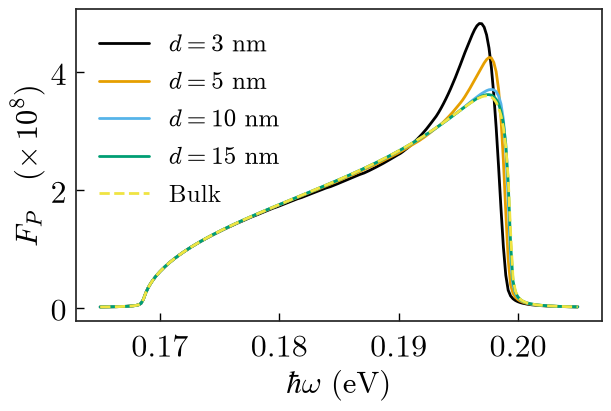

In [68]:
fig, ax = plt.subplots(figsize=(6,4))

for i in range(len(d_ls)):
    
    lam0 = 1240 / omega_ls
    k0 = 2.0 * np.pi / lam0
    im_nGn = k0 * np.sqrt(eps_1) / (6.0 * np.pi)
    Fp = 1 + res[i]['val'] / im_nGn

    if i == len(d_ls)-1:
        ax.plot(omega_ls, Fp*1e-8, label='Bulk', linestyle='--', lw=2)
    else:
        label = r'$d = %.0f \text{ nm}$' % d_ls[i]
        ax.plot(omega_ls, Fp*1e-8, label=label)

ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 18})
ax.set_ylabel(r'$F_P \quad (\times \, 10^{8})$', fontsize=22)
ax.set_xlabel(r'$\hbar\omega \text{ (eV)}$', fontsize=22);